# DSCI-505 | University Admissions Analysis

A university received 17,339 applications across three colleges: Business & Economics, Math & Science, and Arts & Letters.

The university's admissions office wants to understand differences in application volumes, academic performance, and admission outcomes across colleges. As a Business Data Analyst, your task is to analyze the admissions data, identify meaningful patterns, and recommend strategies to improve admission and enrollment planning.
| Column | Description |
|---|---|
| Applicant | Unique applicant ID |
| Sex | Applicant's sex (M/F) |
| SAT_ACT | Standardized admission test score |
| College | College applied to |
| Admitted | Admission offered (Yes/No) |
| Enrolled | Applicant enrolled (Yes/No) |
| Extracurricular_Hours | Weekly hours of extracurricular activities |

## Data Preparation Using Pandas

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Read the Excel file
df = pd.read_excel('applications.xlsx')

# Display the first 5 rows
print(df.head())

# Check for missing values
print(df.isnull().sum())

# Check dataset information
df.info()

   Applicant Sex  SAT_ACT               College Admitted Enrolled  \
0          1   M     1460  Business & Economics      Yes       No   
1          2   F     1180        Math & Science       No       No   
2          3   M     1340        Arts & Letters      Yes       No   
3          4   M     1190  Business & Economics       No       No   
4          5   F     1290  Business & Economics       No       No   

   Extracurricular_Hours  
0                      5  
1                     10  
2                      7  
3                      1  
4                      4  
Applicant                0
Sex                      0
SAT_ACT                  0
College                  0
Admitted                 0
Enrolled                 0
Extracurricular_Hours    0
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 17339 entries, 0 to 17338
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Applicant          

**Data check:** The dataset has 17,339 rows and 7 columns with no missing values, so no rows need to be removed.

---
## Task 01: Bar Plot – Applications by College

Compare the number of applications received by each college. Which college attracts the most applicants?

In [16]:
# Count applications by college
applications = df['College'].value_counts()

# Calculate percentage of applications by college
percentage = round(applications / len(df) * 100, 1)

# Display the counts and percentages
print(applications)
print('\n')
print(percentage)

College
Arts & Letters          6964
Math & Science          6272
Business & Economics    4103
Name: count, dtype: int64


College
Arts & Letters          40.2
Math & Science          36.2
Business & Economics    23.7
Name: count, dtype: float64


### Bar Plot Using Matplotlib

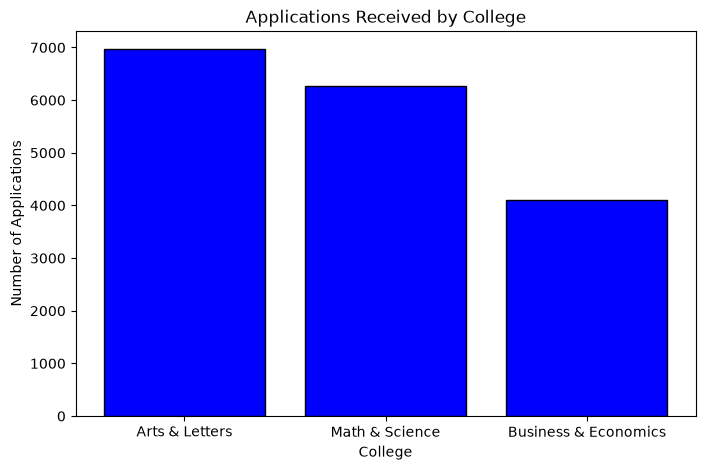

In [3]:
# Set figure size
plt.figure(figsize=(8, 5))

# Create bar plot
plt.bar(applications.index, applications.values, color='blue', edgecolor='black')

# Add title and axis labels
plt.title('Applications Received by College')
plt.xlabel('College')
plt.ylabel('Number of Applications')

# Display the chart
plt.show()

### Bar Plot Using Seaborn

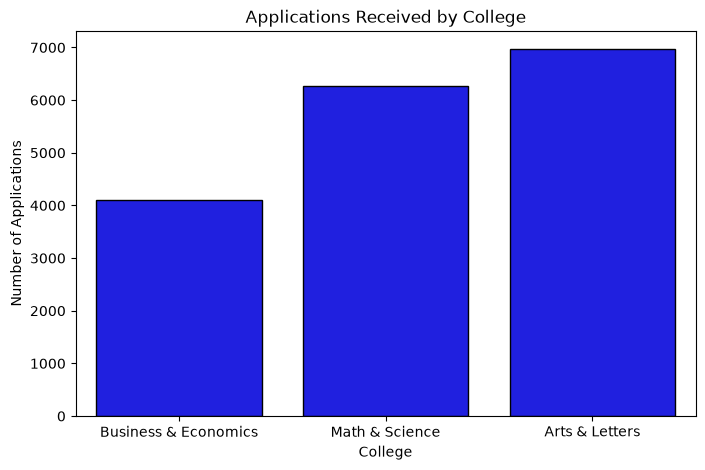

In [4]:
# Set figure size
plt.figure(figsize=(8, 5))

# Create frequency bar plot
sns.countplot(data=df, x='College', color='blue', edgecolor='black')

# Add title and axis labels
plt.title('Applications Received by College')
plt.xlabel('College')
plt.ylabel('Number of Applications')

# Display the chart
plt.show()

### Bar Plot Using Plotly

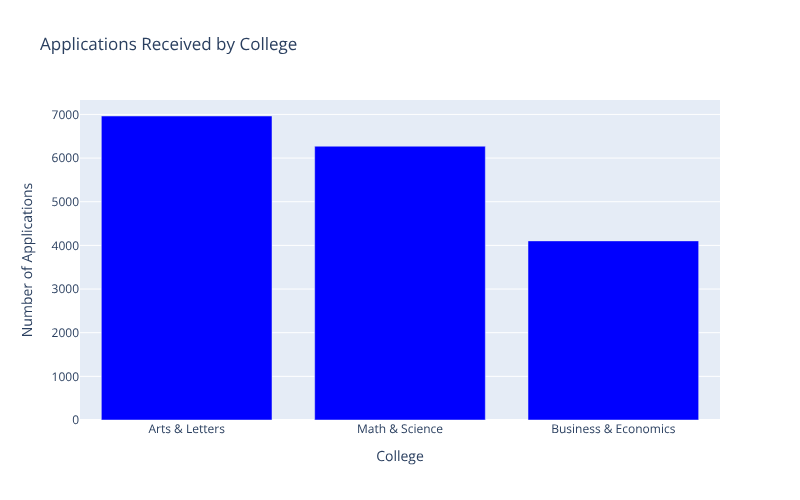

In [5]:
# Create interactive bar plot
fig = px.bar(
    x=applications.index,
    y=applications.values,
    color_discrete_sequence=['blue'],
    title='Applications Received by College',
    labels={'x': 'College', 'y': 'Number of Applications'},
    width=800,
    height=500
)

# Display the interactive chart
fig.show()

### Interpretation
**Arts & Letters** attracts the most applicants with 6,964 applications (40.2% of the total), followed by Math & Science with 6,272 (36.2%) and Business & Economics with 4,103 (23.7%). Arts & Letters receives about 70% more applications than Business & Economics.

---
## Task 02: Histogram – Distribution of SAT_ACT Scores

Visualize the distribution of SAT_ACT scores. What is the most common score range?

In [6]:
# Find the lowest and highest SAT/ACT scores
print("Lowest Score:", df['SAT_ACT'].min())
print("Highest Score:", df['SAT_ACT'].max())

# Define class intervals with a width of 100 points (starting below the lowest score)
bins = [200, 300, 400, 500, 600, 700, 800, 900, 1000, 1100, 1200, 1300, 1400, 1500, 1600]

# Calculate the frequency distribution
frequency, intervals = np.histogram(df['SAT_ACT'], bins=bins)

# Display the frequency distribution
print("Class Intervals:", intervals)
print("Frequencies:", frequency)
print("Highest Frequency:", frequency.max())

Lowest Score: 280
Highest Score: 1600
Class Intervals: [ 200  300  400  500  600  700  800  900 1000 1100 1200 1300 1400 1500
 1600]
Frequencies: [   1    5    1   15   57  276  785 1705 2928 3910 3717 2363 1204  372]
Highest Frequency: 3910


### Histogram Using Matplotlib

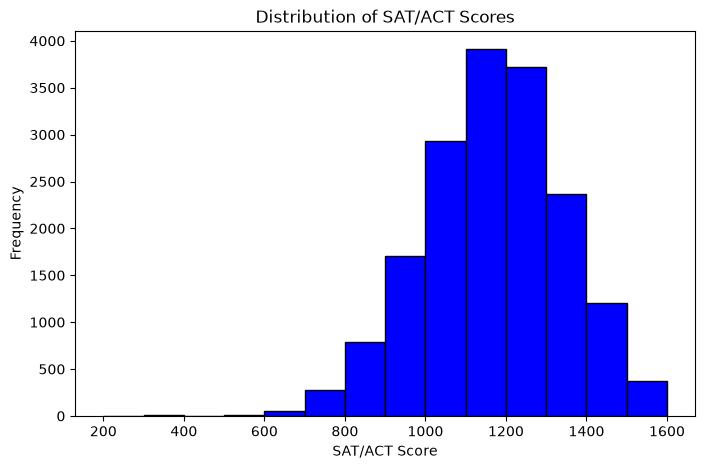

In [7]:
# Set figure size
plt.figure(figsize=(8, 5))

# Create histogram
plt.hist(df['SAT_ACT'], bins=bins, color='blue', edgecolor='black')

# Add title and axis labels
plt.title('Distribution of SAT/ACT Scores')
plt.xlabel('SAT/ACT Score')
plt.ylabel('Frequency')

# Display the chart
plt.show()

### Histogram Using Seaborn

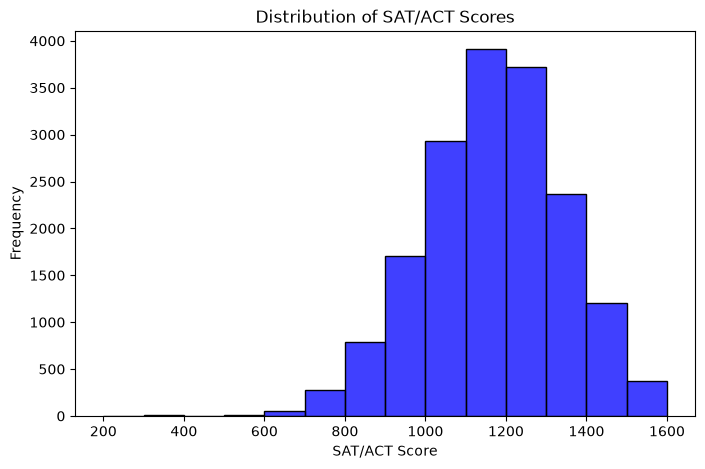

In [8]:
# Set figure size
plt.figure(figsize=(8, 5))

# Create histogram using Seaborn
sns.histplot(data=df, x='SAT_ACT', bins=bins, color='blue', edgecolor='black')

# Add title and axis labels
plt.title('Distribution of SAT/ACT Scores')
plt.xlabel('SAT/ACT Score')
plt.ylabel('Frequency')

# Display the chart
plt.show()

### Histogram Using Plotly

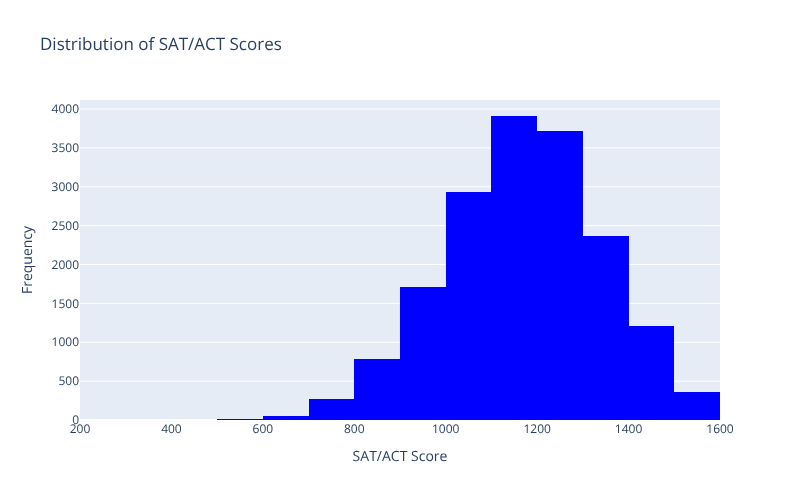

In [9]:
# Create an interactive histogram
fig = px.histogram(
    df,
    x='SAT_ACT',
    color_discrete_sequence=['blue'],
    title='Distribution of SAT/ACT Scores',
    width=800,
    height=500
)

# Set interval width and starting point, and add bar borders
fig.update_traces(xbins=dict(start=200, end=1600, size=100), marker_line_color='black')

# Add axis labels
fig.update_layout(
    xaxis_title='SAT/ACT Score',
    yaxis_title='Frequency'
)

# Display the interactive chart
fig.show()

In [10]:
# Calculate average SAT/ACT score
print("Average Score:", round(df['SAT_ACT'].mean(), 0))

# Count scores below 400, the lowest possible SAT score
print("Scores Below 400:", (df['SAT_ACT'] < 400).sum())

Average Score: 1165.0
Scores Below 400: 6


### Interpretation
The most common score range is **1100 to 1200**, with 3,910 applicants (22.6%), followed closely by 1200 to 1300 with 3,717 applicants. The distribution is roughly bell-shaped around an average score of 1165, with a slightly longer tail toward lower scores. Six scores fall below 400, which is under the SAT minimum, so they may be data entry errors.

---
## Task 03: Scatter Plot – SAT_ACT vs. Extracurricular_Hours

Visualize the relationship between SAT_ACT scores and Extracurricular_Hours. Is there a positive, negative, or no clear relationship?

### Scatter Plot Using Matplotlib

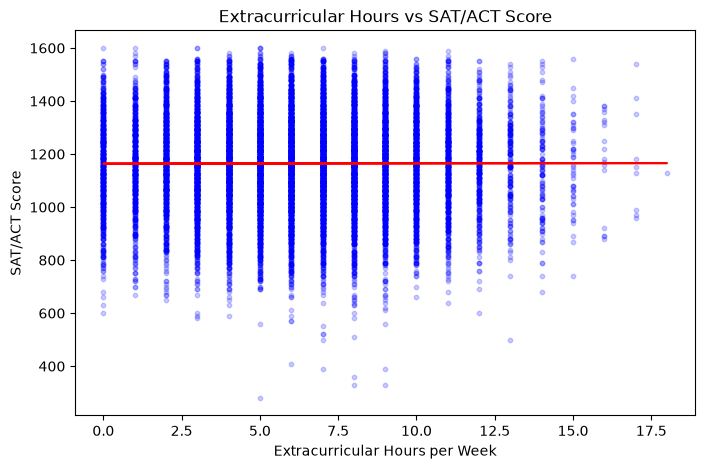

Slope: 0.10661091619843543
Intercept: 1163.9312518954782


In [11]:
# Set figure size
plt.figure(figsize=(8, 5))

# Create a scatter plot
plt.scatter(df['Extracurricular_Hours'], df['SAT_ACT'], color='blue', s=10, alpha=0.2)

# Add a linear trendline
m, b = np.polyfit(df['Extracurricular_Hours'], df['SAT_ACT'], 1)
plt.plot(df['Extracurricular_Hours'], m * df['Extracurricular_Hours'] + b, color='red')

# Add title and axis labels
plt.title('Extracurricular Hours vs SAT/ACT Score')
plt.xlabel('Extracurricular Hours per Week')
plt.ylabel('SAT/ACT Score')

# Display the scatter plot
plt.show()

# Display the trendline slope and intercept
print("Slope:", m)
print("Intercept:", b)

### Scatter Plot Using Seaborn

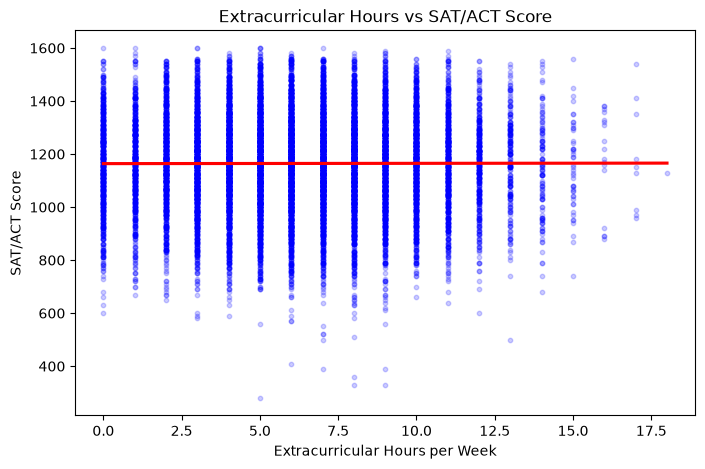

In [12]:
# Set figure size
plt.figure(figsize=(8, 5))

# Create a scatter plot with a trendline
sns.regplot(data=df, x='Extracurricular_Hours', y='SAT_ACT',
            scatter_kws={'color': 'blue', 's': 10, 'alpha': 0.2},
            line_kws={'color': 'red'},
            ci=None)

# Add title and axis labels
plt.title('Extracurricular Hours vs SAT/ACT Score')
plt.xlabel('Extracurricular Hours per Week')
plt.ylabel('SAT/ACT Score')

# Display the scatter plot
plt.show()

### Scatter Plot Using Plotly

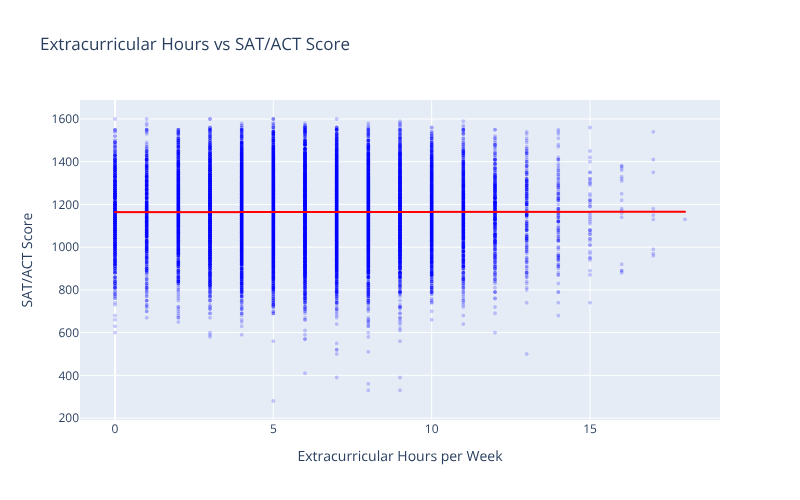

In [13]:
# Create a scatter plot with a trendline
fig = px.scatter(
    df,
    x='Extracurricular_Hours',
    y='SAT_ACT',
    trendline='ols',
    color_discrete_sequence=['blue'],
    title='Extracurricular Hours vs SAT/ACT Score',
    width=800,
    height=500
)

# Set point size and transparency, and trendline color
fig.update_traces(marker_size=4, marker_opacity=0.2, selector=dict(mode='markers'))
fig.update_traces(line_color='red', selector=dict(mode='lines'))

# Add axis labels
fig.update_layout(
    xaxis_title='Extracurricular Hours per Week',
    yaxis_title='SAT/ACT Score'
)

# Display the scatter plot
fig.show()

In [14]:
# Separate applicants with fewer than 6 hours and 6 or more hours
low_hours = df[df['Extracurricular_Hours'] < 6]
high_hours = df[df['Extracurricular_Hours'] >= 6]

# Display average SAT/ACT score for each group
print("Average Score (Less Than 6 Hours):", round(low_hours['SAT_ACT'].mean(), 0))
print("Average Score (6 Hours or More):", round(high_hours['SAT_ACT'].mean(), 0))

Average Score (Less Than 6 Hours): 1166.0
Average Score (6 Hours or More): 1164.0


### Interpretation
**Relationship:** There is **no clear relationship** between extracurricular hours and SAT/ACT scores. At every level of extracurricular hours, scores spread across the same wide range with no upward or downward pattern.

**Trendline:** The red trendline is essentially flat (slope ≈ 0.11 points per hour), so applicants who spend more time on extracurricular activities do not score higher or lower on the SAT/ACT.

**Conclusion:** Applicants with fewer than 6 hours and those with 6 or more hours both average about 1165 on the SAT/ACT. Extracurricular involvement and test performance appear to be independent.

---
## Task 04: Data-Driven Insights

### Finding 1: Application demand is uneven across colleges (Task 01 Bar Plots)
Arts & Letters receives the most applications (6,964, or 40.2%), followed by Math & Science (6,272, or 36.2%). Business & Economics receives the fewest (4,103, or 23.7%), about 41% fewer than Arts & Letters.

**Recommendation:** Increase recruiting for Business & Economics through targeted outreach to high schools, campus events, and messages about career outcomes. At the same time, plan advisors, course sections, and admissions review staff around the higher volume in Arts & Letters so its applicants are processed and served on time.

### Finding 2: Most applicants fall in a middle score range (Task 02 Histograms)
The most common score range is 1100 to 1200 (3,910 applicants), and about three-quarters of applicants score between 1000 and 1400. The distribution is roughly bell-shaped with a slightly longer tail toward lower scores. Six scores fall below 400, which is under the SAT minimum.

**Recommendation:** Build admission and enrollment plans around this central group, such as setting scholarship tiers and forecasting demand for introductory courses and tutoring. Use merit scholarships to compete for the smaller group of applicants scoring 1400 and above (1,576 applicants). Before each cycle, check that all test scores fall within the valid range so data entry errors do not affect planning.

### Finding 3: Extracurricular hours do not predict test scores (Task 03 Scatter Plots)
The trendline is flat in all three scatter plots, and applicants average about the same SAT/ACT score whether they spend fewer or more hours on extracurricular activities. Students who are heavily involved outside the classroom are just as likely to be strong or weak test takers.

**Recommendation:** Evaluate academic readiness and extracurricular involvement as separate criteria instead of assuming one reflects the other. A simple rubric for extracurricular quality, such as leadership roles or awards, would help the admissions office identify applicants who might be overlooked by test scores alone.